# 03. Pemodelan dan Evaluasi
Notebook ini melatih beberapa model untuk memprediksi agent yang dipilih, lalu membandingkannya dengan baseline.

**Definisi "benar".** Satu situasi punya beberapa jawaban yang sama-sama benar, yaitu agent-agent sisa di komposisi aslinya. Maka:
- **top-1 benar** bila agent teratas yang ditebak ada di sisa komposisi asli,
- **top-3 benar** bila salah satu dari tiga agent teratas ada di sisa komposisi asli.

Agent yang **sudah dipilih** tidak boleh direkomendasikan lagi, jadi skornya selalu dimatikan sebelum menilai. Hasil dilaporkan **per jumlah agent yang sudah diketahui** (0 sampai 4).

**Syarat:** notebook 02 sudah dijalankan sehingga `hasil/data_model.npz` dan `hasil/meta_model.json` ada.

**Penjelasan blok 1:** Memuat data siap latih dari notebook 02 dan daftar agent, map, serta fitur. Tiga pengaturan di atas bisa diubah: `MAKS_SAMPEL` untuk mempercepat latihan jika komputer lambat, `COBA_OPSIONAL` untuk ikut melatih model tambahan, dan `LATIH_ULANG_SEMUA` untuk membuat model akhir bagi client.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from math import comb
from pathlib import Path
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

HASIL = Path("hasil")
MAKS_SAMPEL = None        # isi angka (misal 200000) untuk mempercepat latihan; None = pakai semua
COBA_OPSIONAL = False     # True = ikut melatih HistGradientBoosting dan MLP (lebih lama)
LATIH_ULANG_SEMUA = True  # True = di akhir latih ulang model terbaik dengan data 2023-2026 untuk client

d = np.load(HASIL / "data_model.npz")
X_train, y_train, X_test, sisa_test = d["X_train"], d["y_train"], d["X_test"], d["sisa_test"]
with open(HASIL / "meta_model.json") as f:
    meta = json.load(f)
AGENTS, MAPS, FITUR = meta["AGENTS"], meta["MAPS"], meta["FITUR"]
NM, NA = len(MAPS), len(AGENTS)

if MAKS_SAMPEL:
    pilih = np.random.default_rng(0).choice(len(X_train), MAKS_SAMPEL, replace=False)
    X_train, y_train = X_train[pilih], y_train[pilih]

print("latih:", X_train.shape, "| uji:", X_test.shape, "| agent:", NA, "| map:", NM)

latih: (513600, 46) | uji: (54932, 46) | agent: 29 | map: 12


**Penjelasan blok 2:** Mendefinisikan cara menilai. `evaluasi` mengubah skor tiap agent menjadi urutan tebakan, mematikan agent yang sudah dipilih, lalu menghitung top-1 dan top-3 per jumlah agent diketahui. Ditambahkan juga pembanding teori: kalau menebak acak, berapa peluang kena. Semua model nanti dinilai dengan cara yang sama.

In [2]:
K_KENAL = X_test[:, NM + NA].astype(int)              # jumlah agent yang sudah dipilih di tiap situasi uji
SUDAH_DIPILIH = X_test[:, NM:NM + NA] == 1             # agent yang sudah dipilih (tidak boleh direkomendasikan)
BARIS = np.arange(len(X_test))[:, None]

def skor_ke_prediksi(S):
    S = np.where(SUDAH_DIPILIH, -np.inf, S)            # matikan agent yang sudah dipilih
    return np.argsort(-S, axis=1)                      # urutan agent dari skor tertinggi

def evaluasi(S):
    urut = skor_ke_prediksi(S)
    top1 = sisa_test[BARIS, urut[:, :1]].max(axis=1)   # 1 bila agent teratas ada di sisa komposisi asli
    top3 = sisa_test[BARIS, urut[:, :3]].max(axis=1)   # 1 bila salah satu dari 3 teratas ada di sisa
    t1 = {k: top1[K_KENAL == k].mean() for k in range(5)}
    t3 = {k: top3[K_KENAL == k].mean() for k in range(5)}
    t1["semua"], t3["semua"] = top1.mean(), top3.mean()
    return t1, t3

def skor_dari_model(model, X):
    S = np.zeros((len(X), NA))
    S[:, model.classes_] = model.predict_proba(X)      # kolom sesuai nomor agent yang dikenal model
    return S

hasil_top1, hasil_top3, skor = {}, {}, {}

# pembanding teori: menebak acak di antara agent yang belum dipilih
acak1 = {k: (5 - k) / (NA - k) for k in range(5)}
acak3 = {k: 1 - comb(NA - 5, 3) / comb(NA - k, 3) for k in range(5)}
acak1["semua"] = np.mean([acak1[k] for k in K_KENAL]); acak3["semua"] = np.mean([acak3[k] for k in K_KENAL])
hasil_top1["Acak (teori)"], hasil_top3["Acak (teori)"] = acak1, acak3
print("fungsi evaluasi siap")

fungsi evaluasi siap


**Catatan kita:** ...

**Penjelasan blok 3:** Dua baseline sebagai tolok ukur. Baseline 1 selalu menebak agent yang paling sering dipilih secara umum, baseline 2 menebak agent paling sering dipilih di map yang sama. Model kita harus mengalahkan keduanya supaya dianggap berguna. Skor yang sudah dipilih tetap dimatikan oleh fungsi evaluasi.

In [3]:
# Baseline 1: selalu menebak agent yang paling sering dipilih (di seluruh data latih)
hitung_semua = np.bincount(y_train, minlength=NA).astype(float)
S1 = np.tile(hitung_semua, (len(X_test), 1))
hasil_top1["Baseline 1: terpopuler"], hasil_top3["Baseline 1: terpopuler"] = evaluasi(S1)

# Baseline 2: agent yang paling sering dipilih pada map yang sama
map_latih = X_train[:, :NM].argmax(axis=1)
hitung_map = np.zeros((NM, NA))
np.add.at(hitung_map, (map_latih, y_train), 1)
map_uji = X_test[:, :NM].argmax(axis=1)
S2 = hitung_map[map_uji]
hasil_top1["Baseline 2: terpopuler per map"], hasil_top3["Baseline 2: terpopuler per map"] = evaluasi(S2)

print("top-3 baseline 1 (semua):", round(hasil_top3["Baseline 1: terpopuler"]["semua"], 3))
print("top-3 baseline 2 (semua):", round(hasil_top3["Baseline 2: terpopuler per map"]["semua"], 3))

top-3 baseline 1 (semua): 0.574
top-3 baseline 2 (semua): 0.79


**Catatan kita:** ...

**Penjelasan blok 4:** Melatih Logistic Regression (multinomial) dan menilainya. Ini model sederhana dan cepat, cocok sebagai model utama pertama. Parameter dibiarkan bawaan (tanpa tuning), jadi hasilnya bisa dibandingkan secara adil dengan model lain.

In [4]:
t0 = time.time()
lr = LogisticRegression(max_iter=300)
lr.fit(X_train, y_train)
skor["Logistic Regression"] = skor_dari_model(lr, X_test)
hasil_top1["Logistic Regression"], hasil_top3["Logistic Regression"] = evaluasi(skor["Logistic Regression"])
print("selesai dalam", round(time.time() - t0), "detik | top-3 (semua):", round(hasil_top3["Logistic Regression"]["semua"], 3))

selesai dalam 108 detik | top-3 (semua): 0.844


c:\Users\felix\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Penjelasan blok 5:** Melatih Random Forest dan menilainya. Model ini bisa menangkap interaksi antar agent (misalnya agent tertentu sering muncul bersama agent lain). `min_samples_leaf=20` mencegah pohon terlalu menghafal data, dan `n_jobs=-1` memakai semua inti CPU.

In [5]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
skor["Random Forest"] = skor_dari_model(rf, X_test)
hasil_top1["Random Forest"], hasil_top3["Random Forest"] = evaluasi(skor["Random Forest"])
print("selesai dalam", round(time.time() - t0), "detik | top-3 (semua):", round(hasil_top3["Random Forest"]["semua"], 3))

selesai dalam 11 detik | top-3 (semua): 0.85


**Catatan kita:** ...

**Penjelasan blok 6:** Bagian opsional: Gradient Boosting dan MLP. Dilewati secara default karena lebih lama dilatih. Ubah `COBA_OPSIONAL = True` di blok pertama bila ingin ikut membandingkannya.

In [6]:
models = {"Logistic Regression": lr, "Random Forest": rf}

if COBA_OPSIONAL:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.neural_network import MLPClassifier
    for nama, mdl in [("Gradient Boosting", HistGradientBoostingClassifier(max_iter=100, random_state=0)),
                      ("MLP", MLPClassifier(hidden_layer_sizes=(64,), early_stopping=True, max_iter=50, random_state=0))]:
        t0 = time.time()
        mdl.fit(X_train, y_train)
        skor[nama] = skor_dari_model(mdl, X_test)
        hasil_top1[nama], hasil_top3[nama] = evaluasi(skor[nama])
        models[nama] = mdl
        print(nama, "selesai dalam", round(time.time() - t0), "detik | top-3:", round(hasil_top3[nama]["semua"], 3))
else:
    print("model opsional dilewati (COBA_OPSIONAL = False)")

model opsional dilewati (COBA_OPSIONAL = False)


**Penjelasan blok 7:** Menyusun hasil semua model dalam dua tabel (top-1 dan top-3), satu baris per model dan satu kolom per jumlah agent diketahui, lalu menggambarnya. **Cara baca:** bandingkan tiap model dengan dua baseline dan dengan baris Acak. Perhatikan juga bagaimana nilai berubah dari 0 ke 4 agent diketahui.

TOP-1 (agent teratas ada di sisa komposisi asli)
                                0 diketahui  1 diketahui  2 diketahui  3 diketahui  4 diketahui  semua
Acak (teori)                          0.172        0.143        0.111        0.077        0.040  0.096
Baseline 1: terpopuler                0.513        0.467        0.401        0.306        0.175  0.349
Baseline 2: terpopuler per map        0.748        0.703        0.620        0.492        0.301  0.545
Logistic Regression                   0.693        0.700        0.669        0.603        0.417  0.613
Random Forest                         0.785        0.743        0.706        0.635        0.470  0.653

TOP-3 (salah satu dari 3 teratas ada di sisa komposisi asli)
                                0 diketahui  1 diketahui  2 diketahui  3 diketahui  4 diketahui  semua
Acak (teori)                          0.446        0.382        0.308        0.222        0.120  0.266
Baseline 1: terpopuler                0.753        0.717        0

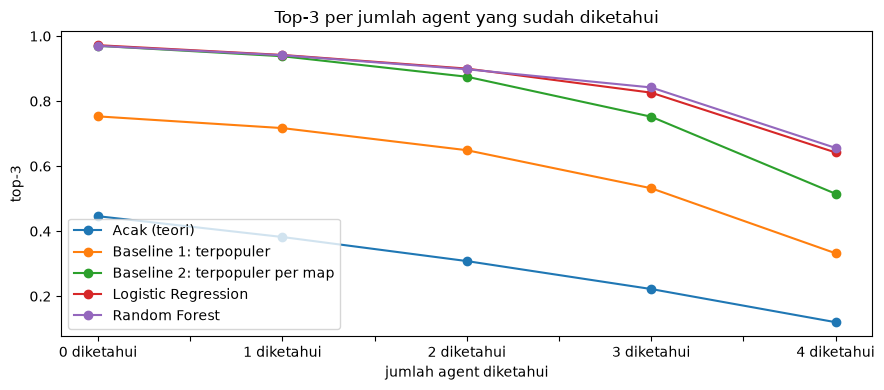

In [7]:
kolom = [0, 1, 2, 3, 4, "semua"]
tabel_top1 = pd.DataFrame(hasil_top1).T[kolom].round(3)
tabel_top3 = pd.DataFrame(hasil_top3).T[kolom].round(3)
tabel_top1.columns = tabel_top3.columns = [f"{k} diketahui" if k != "semua" else "semua" for k in kolom]

print("TOP-1 (agent teratas ada di sisa komposisi asli)")
print(tabel_top1.to_string())
print()
print("TOP-3 (salah satu dari 3 teratas ada di sisa komposisi asli)")
print(tabel_top3.to_string())

tabel_top3.drop(columns="semua").T.plot(marker="o", figsize=(9, 4), title="Top-3 per jumlah agent yang sudah diketahui")
plt.ylabel("top-3"); plt.xlabel("jumlah agent diketahui"); plt.tight_layout(); plt.show()

**Catatan kita:** ...

**Penjelasan blok 8:** Menghitung macro-F1. Macro-F1 butuh satu jawaban benar per baris, sehingga dihitung hanya pada situasi dengan 4 agent diketahui (sisa tepat satu agent). Nilai ini menunjukkan performa rata-rata antar agent, tidak hanya agent yang populer.

In [8]:
m4 = K_KENAL == 4                                       # situasi dengan 4 agent diketahui hanya punya SATU jawaban benar
y_benar4 = sisa_test[m4].argmax(axis=1)

for nama, S in skor.items():
    pred4 = skor_ke_prediksi(S)[m4][:, 0]
    f1 = f1_score(y_benar4, pred4, average="macro", labels=np.unique(y_benar4), zero_division=0)
    print(f"{nama:22s} macro-F1 (4 agent diketahui): {f1:.3f}")

Logistic Regression    macro-F1 (4 agent diketahui): 0.232
Random Forest          macro-F1 (4 agent diketahui): 0.261


**Penjelasan blok 9:** Memilih model terbaik (berdasarkan top-3 keseluruhan) dan melihat agent mana yang paling sulit dan paling mudah ditebak. Ini bahan analisis kesalahan untuk laporan: apakah kesulitan datang dari agent langka, agent baru, atau agent yang bisa menggantikan agent lain.

In [9]:
terbaik = max([n for n in models], key=lambda n: hasil_top3[n]["semua"])
print("model terbaik berdasarkan top-3 (semua):", terbaik)

pred4 = skor_ke_prediksi(skor[terbaik])[m4][:, 0]
baris = []
for j in np.unique(y_benar4):
    n_j = (y_benar4 == j).sum()
    if n_j >= 30:
        baris.append((AGENTS[j], n_j, round((pred4[y_benar4 == j] == j).mean(), 3)))
sulit = pd.DataFrame(baris, columns=["agent", "jumlah_kasus", "recall"]).sort_values("recall")
print("\nagent yang paling sulit ditebak (4 agent diketahui):")
print(sulit.head(8).to_string(index=False))
print("\nagent yang paling mudah ditebak:")
print(sulit.tail(5).to_string(index=False))

model terbaik berdasarkan top-3 (semua): Random Forest

agent yang paling sulit ditebak (4 agent diketahui):
  agent  jumlah_kasus  recall
chamber           212   0.000
 harbor            92   0.000
phoenix           257   0.000
   sage            66   0.000
   veto            75   0.000
 waylay           523   0.015
   vyse           213   0.028
   neon           966   0.106

agent yang paling mudah ditebak:
    agent  jumlah_kasus  recall
    viper           874   0.834
  killjoy           208   0.837
     omen           909   0.846
brimstone           283   0.915
     sova           685   0.915


**Catatan kita:** ...

**Penjelasan blok 10:** Melihat fitur yang paling berpengaruh menurut Random Forest. Ini menjawab tujuan proposal tentang fitur yang paling berdampak. Perhatikan apakah yang terpenting itu map, agent tertentu, atau hitungan peran.

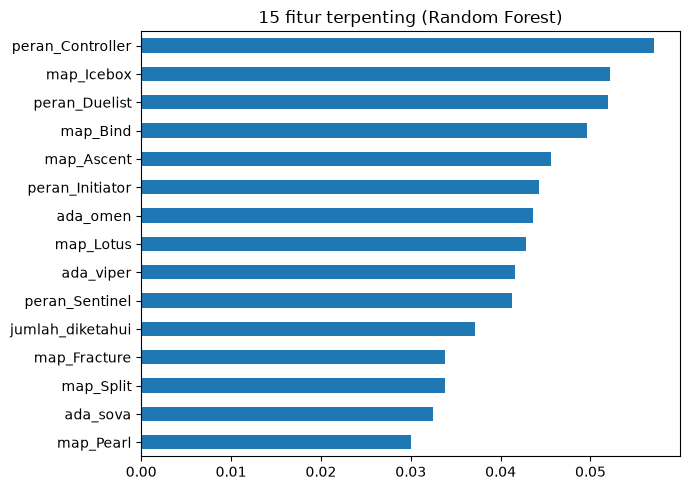

{'peran_Controller': 0.0571, 'map_Icebox': 0.0522, 'peran_Duelist': 0.052, 'map_Bind': 0.0497, 'map_Ascent': 0.0456, 'peran_Initiator': 0.0443, 'ada_omen': 0.0436, 'map_Lotus': 0.0429, 'ada_viper': 0.0416, 'peran_Sentinel': 0.0413}


In [10]:
if "Random Forest" in models:
    penting = pd.Series(models["Random Forest"].feature_importances_, index=FITUR).sort_values(ascending=False)
    penting.head(15).iloc[::-1].plot(kind="barh", figsize=(7, 5), title="15 fitur terpenting (Random Forest)")
    plt.tight_layout(); plt.show()
    print(penting.head(10).round(4).to_dict())

**Catatan kita:** ...

**Penjelasan blok 11:** Menyimpan model terbaik dan tabel hasil. Jika `LATIH_ULANG_SEMUA = True`, model terbaik dilatih ulang dengan data 2023-2026 (termasuk 2026) supaya agent baru seperti Miks dan Veto ikut dikenal. **Model final inilah yang nanti dipakai client**, sedangkan angka evaluasi tetap berasal dari model yang dilatih 2023-2025 dan diuji 2026.

In [11]:
joblib.dump(models[terbaik], HASIL / "model_terbaik_2023_2025.joblib")
tabel_top1.to_csv(HASIL / "hasil_top1.csv")
tabel_top3.to_csv(HASIL / "hasil_top3.csv")
print("tersimpan: model_terbaik_2023_2025.joblib, hasil_top1.csv, hasil_top3.csv")

if LATIH_ULANG_SEMUA:
    baris_u, label_u = np.nonzero(sisa_test)                   # perbanyak data 2026 seperti pada data latih
    X_semua = np.vstack([X_train, X_test[baris_u]])
    y_semua = np.concatenate([y_train, label_u])
    t0 = time.time()
    final = clone(models[terbaik]).fit(X_semua, y_semua)
    joblib.dump(final, HASIL / "model_final_2023_2026.joblib")
    print("model final (data 2023-2026) tersimpan dalam", round(time.time() - t0), "detik | agent yang dikenal:", len(final.classes_), "dari", NA)

tersimpan: model_terbaik_2023_2025.joblib, hasil_top1.csv, hasil_top3.csv
model final (data 2023-2026) tersimpan dalam 14 detik | agent yang dikenal: 29 dari 29


## Kesimpulan pemodelan
Tulis dengan kata kalian sendiri:
1. Apakah model mengalahkan baseline dan tebakan acak, dan seberapa jauh?
2. Bagaimana performa berubah dari 0 sampai 4 agent diketahui, dan kenapa?
3. Model mana yang terbaik, dan apakah selisihnya dengan model lain berarti?
4. Agent mana yang sulit ditebak, dan apa penjelasannya?
5. Keterbatasan: tidak ada tuning dan pemilihan model memakai data uji yang sama, jadi angkanya bisa sedikit optimistis.